In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Visual styling for executive-ready charts
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [5]:
# 1. Load dataset (adjusted to read from the available .zip file)
df = pd.read_csv('/content/online_retail_II.csv.zip')

# Quick check of raw dimensions and column names
print(f"Raw dataset shape: {df.shape}")
print(df.columns.tolist())

Raw dataset shape: (1067371, 8)
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [6]:
# 2. Remove cancelled orders (Invoices starting with 'C')
df_clean = df[~df['Invoice'].astype(str).str.startswith('C')].copy()

# 3. Keep only strictly positive quantities and unit prices
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['Price'] > 0)]

# 4. Remove non-physical service codes (shipping, bank fees, manual adjustments)
non_physical_codes = ['POST', 'D', 'M', 'PADS', 'DOT', 'CRUK', 'BANK CHARGES', 'ADJUST', 'ADJUST2']
df_clean = df_clean[~df_clean['StockCode'].astype(str).isin(non_physical_codes)]

# 5. Drop rows missing essential identifiers
df_clean = df_clean.dropna(subset=['StockCode', 'Description'])

# 6. Compute line-item Revenue and parse dates
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['Price']
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

print(f"Cleaned dataset shape: {df_clean.shape}")



Cleaned dataset shape: (1037376, 9)


In [7]:
# Resample daily/intraday transactions into weekly demand buckets (Monday-based)
weekly_demand = (
    df_clean
    .set_index('InvoiceDate')
    .groupby('StockCode')
    .resample('W-MON')['Quantity']
    .sum()
    .unstack(level=0, fill_value=0) # Fill weeks with zero sales explicitly with 0
    .T # Transpose: SKUs as rows, Weeks as columns
)

print(f"Weekly demand matrix shape (SKUs x Weeks): {weekly_demand.shape}")
weekly_demand.iloc[:5, :5]

Weekly demand matrix shape (SKUs x Weeks): (4909, 106)


InvoiceDate,2009-12-07,2009-12-14,2009-12-21,2009-12-28,2010-01-04
StockCode,,,,,
10002,143,59,12,2,3
10002R,1,0,2,0,0
10080,4,0,0,0,0
10109,4,0,0,0,0
10120,100,8,6,1,30


In [8]:
# --- PART A: ABC Analysis (Economic Value / Pareto) ---
sku_summary = df_clean.groupby('StockCode').agg(
    Total_Revenue=('Revenue', 'sum'),
    Avg_Price=('Price', 'mean')
).sort_values(by='Total_Revenue', ascending=False).reset_index()

sku_summary['Cumulative_Revenue'] = sku_summary['Total_Revenue'].cumsum()
sku_summary['Cumulative_Share'] = sku_summary['Cumulative_Revenue'] / sku_summary['Total_Revenue'].sum()

# Assign ABC classes (80% / 15% / 5% rule)
sku_summary['Class_ABC'] = np.select(
    [sku_summary['Cumulative_Share'] <= 0.80, sku_summary['Cumulative_Share'] <= 0.95],
    ['A', 'B'],
    default='C'
)

# --- PART B: XYZ Analysis (Demand Volatility) ---
demand_stats = pd.DataFrame({
    'StockCode': weekly_demand.index,
    'Mean_Demand': weekly_demand.mean(axis=1),
    'Std_Demand': weekly_demand.std(axis=1)
}).reset_index(drop=True)

# Coefficient of Variation (CV = std / mean)
demand_stats['CV'] = np.where(
    demand_stats['Mean_Demand'] > 0,
    demand_stats['Std_Demand'] / demand_stats['Mean_Demand'],
    np.nan
)

# Assign XYZ classes
demand_stats['Class_XYZ'] = np.select(
    [demand_stats['CV'] < 0.5, demand_stats['CV'] < 1.0],
    ['X', 'Y'],
    default='Z'
)

# --- PART C: Merge into the final ABC-XYZ Matrix ---
matrix_df = pd.merge(sku_summary, demand_stats, on='StockCode', how='inner').dropna(subset=['CV'])
matrix_df['Matrix_Class'] = matrix_df['Class_ABC'] + matrix_df['Class_XYZ']

print(matrix_df['Matrix_Class'].value_counts().sort_index())

Matrix_Class
AX       2
AY     187
AZ     847
BY      27
BZ    1253
CZ    2593
Name: count, dtype: int64


In [10]:
# Realistic supplier parameters (in weeks)
LT_mean = 2.0  # Average replenishment lead time: 2 weeks
LT_std = 0.5   # Supplier delivery variability: 0.5 weeks

# Test Service Levels from 90% to 99%
service_levels = [0.90, 0.92, 0.95, 0.97, 0.98, 0.99]
sensitivity_results = []

# Pre-compute the combined demand & lead-time standard deviation for every SKU
combined_std = np.sqrt(
    (LT_mean * (matrix_df['Std_Demand'] ** 2)) +
    ((matrix_df['Mean_Demand'] ** 2) * (LT_std ** 2))
)

for sl in service_levels:
    z_factor = stats.norm.ppf(sl) # Exact Z-score from Standard Normal distribution

    # Safety Stock in physical units
    ss_units = z_factor * combined_std

    # Monetary Working Capital tied up in Safety Stock
    tied_capital = (ss_units * matrix_df['Avg_Price']).sum()

    sensitivity_results.append({
        'Service_Level_Pct': sl * 100,
        'Z_Factor': round(z_factor, 2),
        'Tied_Capital_EUR': round(tied_capital, 2)
    })

sensitivity_df = pd.DataFrame(sensitivity_results)
print(sensitivity_df)

   Service_Level_Pct  Z_Factor  Tied_Capital_EUR
0               90.0      1.28         941539.95
1               92.0      1.41        1032288.55
2               95.0      1.64        1208453.45
3               97.0      1.88        1381795.61
4               98.0      2.05        1508863.71
5               99.0      2.33        1709138.77


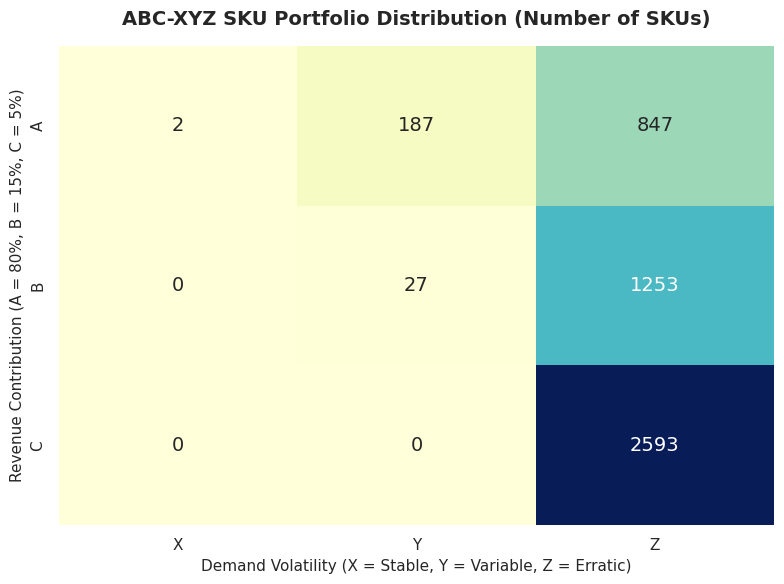

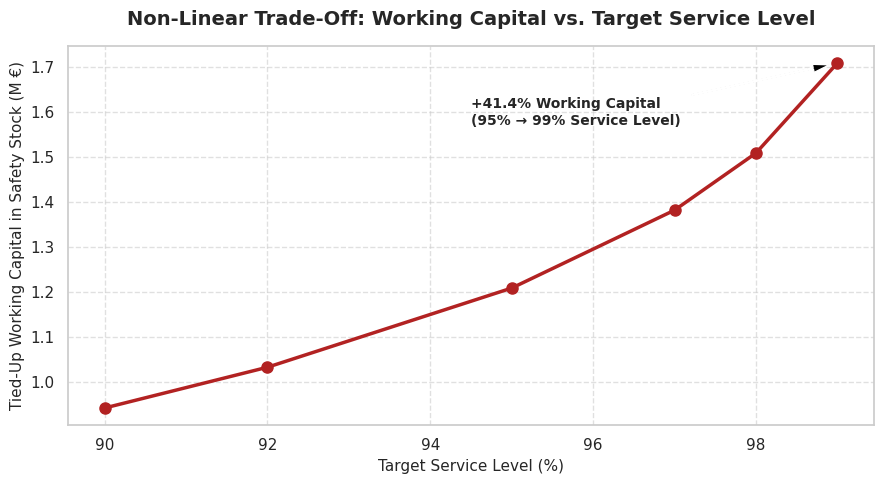

In [11]:
# 1. Heatmap: ABC-XYZ SKU Portfolio Distribution
pivot_matrix = pd.crosstab(matrix_df['Class_ABC'], matrix_df['Class_XYZ']).reindex(
    index=['A', 'B', 'C'], columns=['X', 'Y', 'Z'], fill_value=0
)

plt.figure(figsize=(8, 6))
sns.heatmap(pivot_matrix, annot=True, fmt='d', cmap='YlGnBu', cbar=False, annot_kws={"size": 14})
plt.title("ABC-XYZ SKU Portfolio Distribution (Number of SKUs)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Demand Volatility (X = Stable, Y = Variable, Z = Erratic)", fontsize=11)
plt.ylabel("Revenue Contribution (A = 80%, B = 15%, C = 5%)", fontsize=11)
plt.tight_layout()
plt.savefig("abc_xyz_heatmap.png", dpi=300)
plt.show()

# 2. Trade-off Curve: Tied-Up Working Capital vs. Service Level
plt.figure(figsize=(9, 5))
plt.plot(
    sensitivity_df['Service_Level_Pct'],
    sensitivity_df['Tied_Capital_EUR'] / 1e6,
    marker='o', color='#b22222', linewidth=2.5, markersize=8
)
plt.title("Non-Linear Trade-Off: Working Capital vs. Target Service Level", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Target Service Level (%)", fontsize=11)
plt.ylabel("Tied-Up Working Capital in Safety Stock (M €)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

# Annotate the critical 95% -> 99% jump dynamically
cap_95 = sensitivity_df.loc[sensitivity_df['Service_Level_Pct'] == 95.0, 'Tied_Capital_EUR'].values[0] / 1e6
cap_99 = sensitivity_df.loc[sensitivity_df['Service_Level_Pct'] == 99.0, 'Tied_Capital_EUR'].values[0] / 1e6
jump_pct = ((cap_99 - cap_95) / cap_95) * 100

plt.annotate(
    f"+{jump_pct:.1f}% Working Capital\n(95% → 99% Service Level)",
    xy=(99, cap_99), xytext=(94.5, cap_99 * 0.92),
    arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6),
    fontweight='bold', fontsize=10
)

plt.tight_layout()
plt.savefig("working_capital_tradeoff.png", dpi=300)
plt.show()